   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.2 MB/s eta 0:00:00


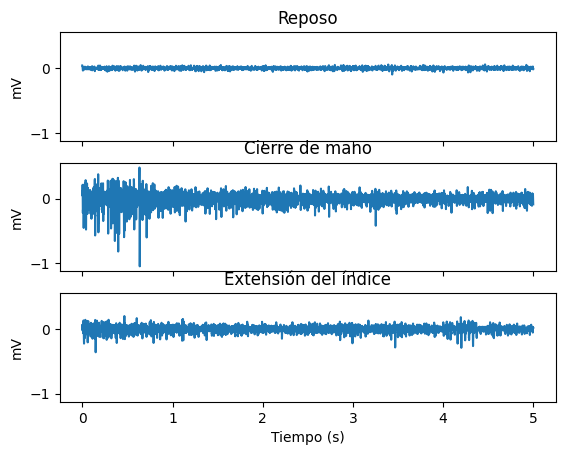

In [1]:
!pip install wfdb
import wfdb
import numpy as np
import matplotlib.pyplot as plt

carpeta = "grabmyo/1.1.0/Session1/session1_participant1"
gestos = {"Reposo": 17, "Cierre de mano": 16, "Extensión del índice": 9}
canal = 11  # Canal F12 es el índice 11 en Python

senales = {}
for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(f"session1_participant1_gesture{k}_trial1", pn_dir=carpeta)
    senales[nombre_g] = rec.p_signal[:, canal]

# Graficar para verificar amplitudes
fig, ax = plt.subplots(3, 1, sharex=True, sharey=True)
for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")
ax[-1].set_xlabel("Tiempo (s)")
plt.show()

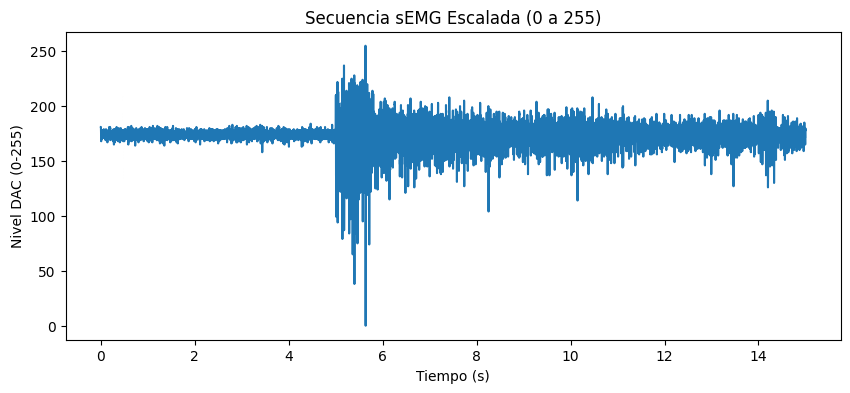

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# Concatenar señales: Reposo -> Cierre de mano -> Extensión de índice
secuencia = np.concatenate([senales["Reposo"], senales["Cierre de mano"], senales["Extensión del índice"]])

# Escalado lineal único de toda la secuencia al rango [0, 255]
min_val = np.min(secuencia)
max_val = np.max(secuencia)
secuencia_escalada = ((secuencia - min_val) / (max_val - min_val) * 255).astype(np.uint8)

# Graficar la secuencia final escalada
plt.figure(figsize=(10, 4))
plt.plot(np.arange(len(secuencia_escalada)) / 2048, secuencia_escalada)
plt.title("Secuencia sEMG Escalada (0 a 255)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Nivel DAC (0-255)")
plt.show()

# Crear el archivo semg.h
with open("semg.h", "w") as f:
    f.write("#ifndef SEMG_H\n#define SEMG_H\n\n")
    f.write("#include <Arduino.h>\n\n")
    f.write(f"const uint16_t N_SEMG = {len(secuencia_escalada)};\n")
    f.write("const uint16_t FS_SEMG = 2048;\n\n")
    f.write("const uint8_t SEMG[] PROGMEM = {\n  ")

    # Formatear el arreglo de valores separados por comas
    valores_str = ", ".join(map(str, secuencia_escalada))
    f.write(valores_str)

    f.write("\n};\n\n#endif\n")

# Descargar semg.h
from google.colab import files
files.download("semg.h")